# 파이프라인 전체 평가 (분류기 → Gemini → 영양 모델)

`n296/eval_pipeline.py` 결과(`runs/pipeline_eval/`)를 시각화한다.

```
이미지 → 음식 분류기 (확신도 < 0.7 이면 Gemini 3.5-flash-lite 가 음식명) → Gemini 재료
      → "음식명 (재료: …)" 임베딩 + 이미지·주파수 특징 → 영양 모델 (runs/nutrition_cls109)
```

| 테스트 세트 | 내용 | 정답 |
|---|---|---|
| **aihub122** | 분류기 test 분할에서 음식마다 1장 (109종) — 분류기가 **아는** 음식 | 영양DB 1인분 |
| **test296** | test_dataset_296 에서 음식마다 서로 다른 샘플 3장 (19종) — 분류기가 **모르는** 음식 | 296 라벨 1인분 |

- **oracle** (aihub122 만): 정답 음식명 + 영양DB 재료로 같은 영양 모델을 돌린 값. pipeline − oracle = 음식명·재료 인식 오차.
- aihub122 의 `nut_seen=False` 26장은 **영양 모델**에게는 처음 보는 음식이다 (분류기는 학습함).
- PMAE = 100 × MAE / 정답 평균 (%), mean PMAE = 칼로리·지방·단백질 평균.

그림은 `runs/pipeline_eval/figures/` 에도 저장한다.

In [1]:
import os, sys, json
ROOT = "/home/students/cs/202321024/2025_2/diet-management/n296_stage3"
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from PIL import Image
from IPython.display import display
from n296.common import load_config, resolve, TARGETS
from n296.metrics import compute_metrics

load_config("configs/cls109_nutrition.yaml")
RUN = resolve("runs/pipeline_eval")
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e8e7e3"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
mpl.rcParams.update({
    "font.family": "Noto Sans CJK JP", "axes.unicode_minus": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "lines.linewidth": 2, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def pmae(df, prefix="pred"):
    m = compute_metrics({k: df[f"{prefix}_{k}"].values for k in TARGETS}, {k: df[f"gt_{k}"].values for k in TARGETS})
    return {k: m[k] for k in ("cal", "fat", "prot", "mass", "carb_head", "mean_pmae")}

res = pd.read_csv(RUN / "results.csv")
summary = json.loads((RUN / "summary.json").read_text())
A = res[res["set"] == "aihub122"].copy()
B = res[res["set"] == "test296"].copy()
for d in (A, B):
    d["kcal_err_pct"] = 100 * (d["pred_calories"] - d["gt_calories"]) / d["gt_calories"]
A["oracle_kcal_err_pct"] = 100 * (A["oracle_calories"] - A["gt_calories"]) / A["gt_calories"]
print(res.groupby("set").size().to_string())

set
aihub122    109
test296      57


## 1. 요약

In [2]:
rows = []
for name, d in (("aihub122 (분류기가 아는 음식)", A), ("test296 (분류기가 모르는 음식)", B)):
    p = pmae(d)
    rows.append({"세트": name, "사진": len(d), "음식": d["gt_name"].nunique(),
                 "Gemini 로 넘어간 비율 %": 100 * (d["name_source"] == "gemini").mean(),
                 "음식명 정확도 %": 100 * d["name_correct"].mean(),
                 "칼로리 PMAE": p["cal"], "mean PMAE (pipeline)": p["mean_pmae"],
                 "mean PMAE (oracle)": pmae(d, "oracle")["mean_pmae"] if name.startswith("aihub") else np.nan})
display(pd.DataFrame(rows).set_index("세트").round(1))
print("test296 의 음식명 정확도는 이름이 정확히 같을 때만 정답이라 거의 0 이다 (분류기·영양DB 에 없는 음식명).")

,사진,음식,Gemini 로 넘어간 비율 %,음식명 정확도 %,칼로리 PMAE,mean PMAE (pipeline),mean PMAE (oracle)
세트,,,,,,,
aihub122 (분류기가 아는 음식),109,109,14.7,78.0,15.8,20.6,11.4
test296 (분류기가 모르는 음식),57,19,71.9,5.3,44.7,51.0,NaN


test296 의 음식명 정확도는 이름이 정확히 같을 때만 정답이라 거의 0 이다 (분류기·영양DB 에 없는 음식명).


## 2. 음식명: 어디서 정해졌고 맞았나 (aihub122)

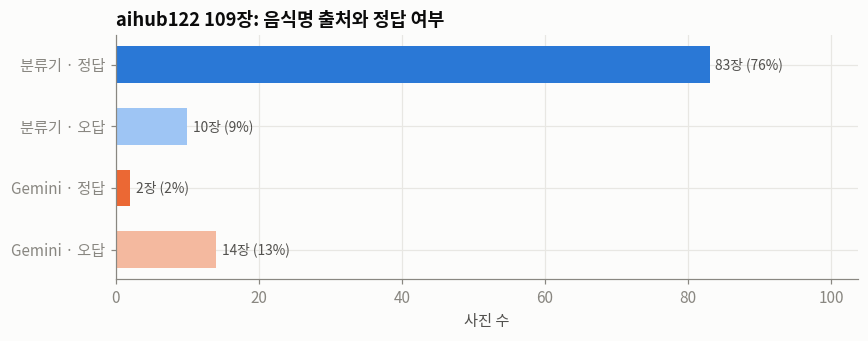

Gemini 로 넘어간 사진


,정답,분류기 top1,분류기 확신도,Gemini 음식명
0,(검은)콩조림,깨죽,0.65,검은콩조림
1,가자미조림,가자미조림,0.57,생선조림
2,갈치조림,갈치조림,0.54,대구조림
3,돼지갈비찜,찜닭,0.65,돼지갈비찜
4,두부고추장조림,두부고추장조림,0.58,두부조림
5,들깨칼국수,들깨칼국수,0.50,버섯 칼국수
6,떡라면,떡라면,0.24,라면
7,막국수,물냉면,0.45,냉메밀국수
8,메밀국수,돈가스,0.54,모밀소바
9,메추리알장조림,메추리알장조림,0.40,메추리알조림


분류기가 확신(≥0.7)했지만 틀린 사진


,정답,분류기 예측,확신도
0,깐풍기,닭강정,0.84
1,라면,짬뽕라면,1.00
2,물만두,고기만두,0.99
3,비빔국수,쫄면,0.73
4,양념치킨,북어조림,0.94
5,일식우동,김치우동,0.73
6,잔치국수,쌀국수,0.84
7,짬뽕,삼선짬뽕,0.74
8,탕수육,닭튀김,0.96
9,해물칼국수,수제비,0.93


In [3]:
cat = pd.Series(np.select(
    [(A["name_source"] == "classifier") & A["name_correct"], (A["name_source"] == "classifier") & ~A["name_correct"],
     (A["name_source"] == "gemini") & A["name_correct"], (A["name_source"] == "gemini") & ~A["name_correct"]],
    ["분류기 · 정답", "분류기 · 오답", "Gemini · 정답", "Gemini · 오답"]), index=A.index)
cnt = cat.value_counts().reindex(["분류기 · 정답", "분류기 · 오답", "Gemini · 정답", "Gemini · 오답"]).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 3.2))
colors = [C1, "#9ec5f4", C2, "#f4b99f"]
ax.barh(cnt.index[::-1], cnt.values[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(cnt.values[::-1]):
    ax.text(v + 0.8, y, f"{v}장 ({100*v/len(A):.0f}%)", va="center", color=INK2, fontsize=9)
ax.set(title=f"aihub122 {len(A)}장: 음식명 출처와 정답 여부", xlabel="사진 수", xlim=(0, cnt.max() * 1.25))
fig.tight_layout(); save(fig, "01_name_source"); plt.show()
g = A[A["name_source"] == "gemini"][["gt_name", "cls_name", "cls_prob", "food_name"]]
g.columns = ["정답", "분류기 top1", "분류기 확신도", "Gemini 음식명"]
print("Gemini 로 넘어간 사진"); display(g.round(2).reset_index(drop=True))
w = A[(A["name_source"] == "classifier") & ~A["name_correct"]][["gt_name", "cls_name", "cls_prob"]]
w.columns = ["정답", "분류기 예측", "확신도"]
print("분류기가 확신(≥0.7)했지만 틀린 사진"); display(w.round(2).reset_index(drop=True))

## 3. 음식명 (test296: 분류기가 모르는 음식)

정답 이름이 분류기·영양DB 에 없으므로 이름 일치 대신 무엇으로 예측됐는지 본다.

In [4]:
t = B.groupby("gt_name").agg(
    Gemini비율=("name_source", lambda s: (s == "gemini").mean()),
    최종음식명=("food_name", lambda s: ", ".join(pd.Series(s).value_counts().index[:3])),
    분류기top1=("cls_name", lambda s: ", ".join(pd.Series(s).value_counts().index[:2])),
    평균확신도=("cls_prob", "mean"))
display(t.round(2))
print(f"분류기가 확신(≥0.7)해 Gemini 를 거치지 않은 사진: {(B['name_source'] == 'classifier').sum()} / {len(B)}장")

,Gemini비율,최종음식명,분류기top1,평균확신도
gt_name,,,,
간장닭갈비,1.00,"닭강정, 찜닭","닭강정, 땅콩조림",0.41
갈비전골,1.00,"갈비탕, 소고기무국","어죽, 소고기메추리알장조림",0.31
감자만두,0.67,"감자만두, 고기만두, 만두","물만두, 고기만두",0.56
감자옹심이,0.67,"수제비, 만둣국, 떡국","떡국, 해물칼국수",0.45
낙곱새,1.00,"낙곱새, 떡볶이, 제육볶음","회냉면, 비빔국수",0.35
냉채족발,0.67,"족발, 샐러드","치즈돈가스, 족발",0.45
대하구이,0.67,"새우구이, 해물찜","새우튀김, 해물찜",0.69
등갈비찜,1.00,"떡볶이, 닭볶음탕, 갈비찜","토마토스프, 짬뽕",0.52
멘보샤,0.67,"멘보샤, 토스트, 두부고추장조림","오징어튀김, 고구마맛탕",0.55


분류기가 확신(≥0.7)해 Gemini 를 거치지 않은 사진: 16 / 57장


## 4. 영양 오차 비교 (mean PMAE)

oracle 은 정답 음식명 + 영양DB 재료를 넣은 경우 (aihub122 만 계산 가능).

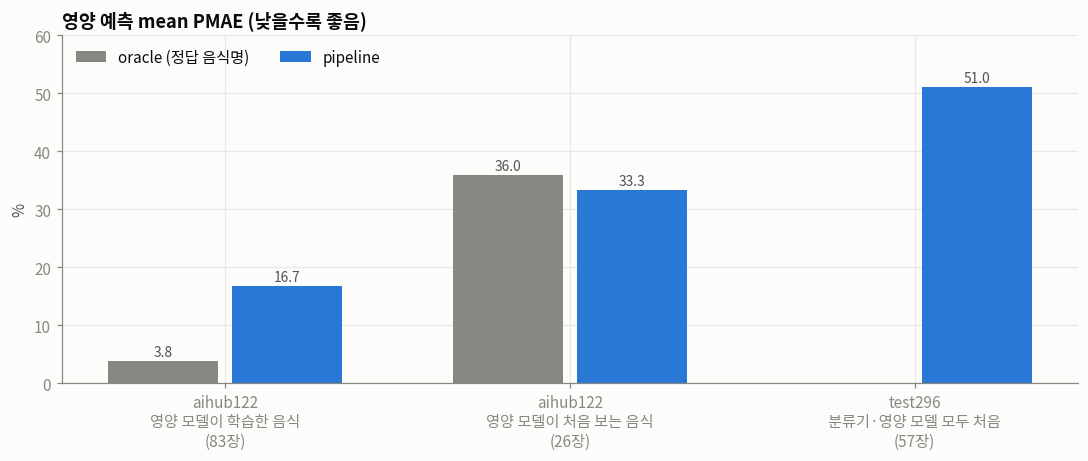

cal   fat  prot  mass  carb_head  \
세트                       입력                                            
aihub122 영양 모델이 학습한 음식   oracle     3.1   4.3   4.1   4.2        4.2   
                         pipeline  12.3  20.6  17.3  10.9       11.2   
aihub122 영양 모델이 처음 보는 음식 oracle    30.9  45.0  32.1  19.7       33.9   
                         pipeline  27.6  40.3  32.0  19.0       32.7   
test296 분류기·영양 모델 모두 처음  pipeline  44.7  54.6  53.8  59.9       58.7   

                                   mean_pmae  
세트                       입력                   
aihub122 영양 모델이 학습한 음식   oracle          3.8  
                         pipeline       16.7  
aihub122 영양 모델이 처음 보는 음식 oracle         36.0  
                         pipeline       33.3  
test296 분류기·영양 모델 모두 처음  pipeline       51.0

In [5]:
groups = [("aihub122\n영양 모델이 학습한 음식", A[A["nut_seen"]]),
          ("aihub122\n영양 모델이 처음 보는 음식", A[~A["nut_seen"]]),
          ("test296\n분류기·영양 모델 모두 처음", B)]
fig, ax = plt.subplots(figsize=(10, 4.3))
x = np.arange(len(groups)); w = 0.36
for i, (lab, prefix, c) in enumerate((("oracle (정답 음식명)", "oracle", MUTED), ("pipeline", "pred", C1))):
    vals = [pmae(d, prefix)["mean_pmae"] if not (prefix == "oracle" and d["oracle_calories"].isna().all()) else np.nan for _, d in groups]
    bars = ax.bar(x + (i - 0.5) * w, vals, w - 0.04, color=c, label=lab)
    for b, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, [f"{lab}\n({len(d)}장)" for lab, d in groups])
ax.set(title="영양 예측 mean PMAE (낮을수록 좋음)", ylabel="%")
ax.set_ylim(0, max(ax.get_ylim()[1], 10) * 1.12)
ax.legend(frameon=False, loc="upper left", ncol=2)
fig.tight_layout(); save(fig, "02_pmae_compare"); plt.show()
tab = []
for lab, d in groups:
    for prefix in ("oracle", "pred"):
        if prefix == "oracle" and d["oracle_calories"].isna().all():
            continue
        tab.append({"세트": lab.replace("\n", " "), "입력": "oracle" if prefix == "oracle" else "pipeline", **pmae(d, prefix)})
display(pd.DataFrame(tab).set_index(["세트", "입력"]).round(1))

## 5. 음식명이 틀리면 영양 오차가 얼마나 커지나 (aihub122)

사진별 칼로리 오차(%)의 분포. 점 = 사진 1장.

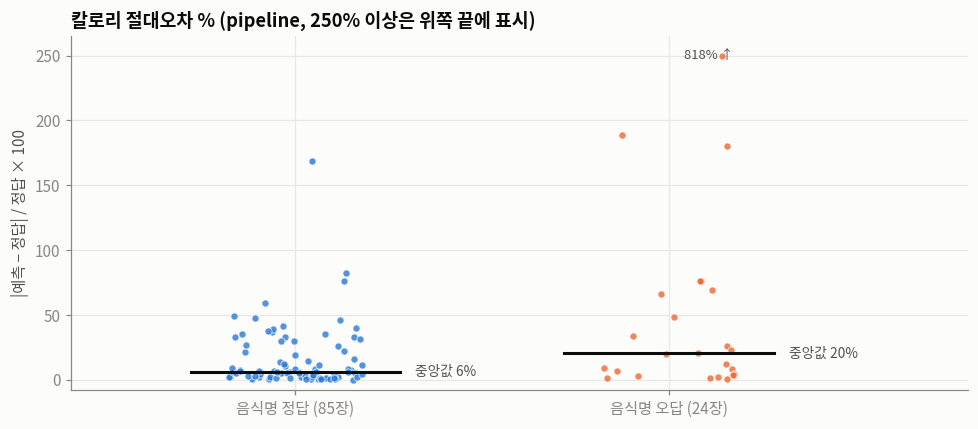

,정답,예측 음식명,출처,정답 kcal,pipeline kcal,oracle kcal
0,(검은)콩조림,검은콩조림,gemini,57.0,100.0,100.0
1,가자미조림,생선조림,gemini,301.0,363.0,313.0
2,갈치조림,대구조림,gemini,99.0,278.0,294.0
3,깐풍기,닭강정,classifier,585.0,626.0,390.0
4,두부고추장조림,두부조림,gemini,67.0,119.0,82.0
5,들깨칼국수,버섯 칼국수,gemini,442.0,558.0,438.0
6,떡라면,라면,gemini,672.0,615.0,673.0
7,라면,짬뽕라면,classifier,509.0,555.0,500.0
8,막국수,냉메밀국수,gemini,567.0,553.0,557.0
9,메밀국수,모밀소바,gemini,589.0,562.0,577.0


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
cats = [("음식명 정답", A[A["name_correct"]], C1), ("음식명 오답", A[~A["name_correct"]], C2)]
CAP = 250  # 이보다 큰 값은 위쪽 끝에 표시
rng = np.random.default_rng(0)
for i, (lab, d, c) in enumerate(cats):
    y = d["kcal_err_pct"].abs().values
    yc = np.minimum(y, CAP)
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(y)), yc, color=c, s=22, alpha=0.8, edgecolor=SURFACE, lw=0.6)
    for v in y[y > CAP]:
        ax.annotate(f"{v:.0f}% ↑", (i, CAP), xytext=(10, -2), textcoords="offset points", color=INK2, fontsize=8.5)
    if len(y):
        ax.plot([i - 0.28, i + 0.28], [np.median(y)] * 2, color=INK, lw=2)
        ax.text(i + 0.32, np.median(y), f"중앙값 {np.median(y):.0f}%", va="center", color=INK2, fontsize=9)
ax.set_xticks(range(len(cats)), [f"{lab} ({len(d)}장)" for lab, d, _ in cats])
ax.set(title="칼로리 절대오차 % (pipeline, 250% 이상은 위쪽 끝에 표시)", ylabel="|예측 − 정답| / 정답 × 100",
       xlim=(-0.6, len(cats) - 0.2), ylim=(-8, CAP + 15))
fig.tight_layout(); save(fig, "03_error_by_name"); plt.show()
bad = A[~A["name_correct"]][["gt_name", "food_name", "name_source", "gt_calories", "pred_calories", "oracle_calories"]].copy()
bad.columns = ["정답", "예측 음식명", "출처", "정답 kcal", "pipeline kcal", "oracle kcal"]
display(bad.round(0).sort_values("정답").reset_index(drop=True))

## 6. 칼로리: 정답 vs 예측

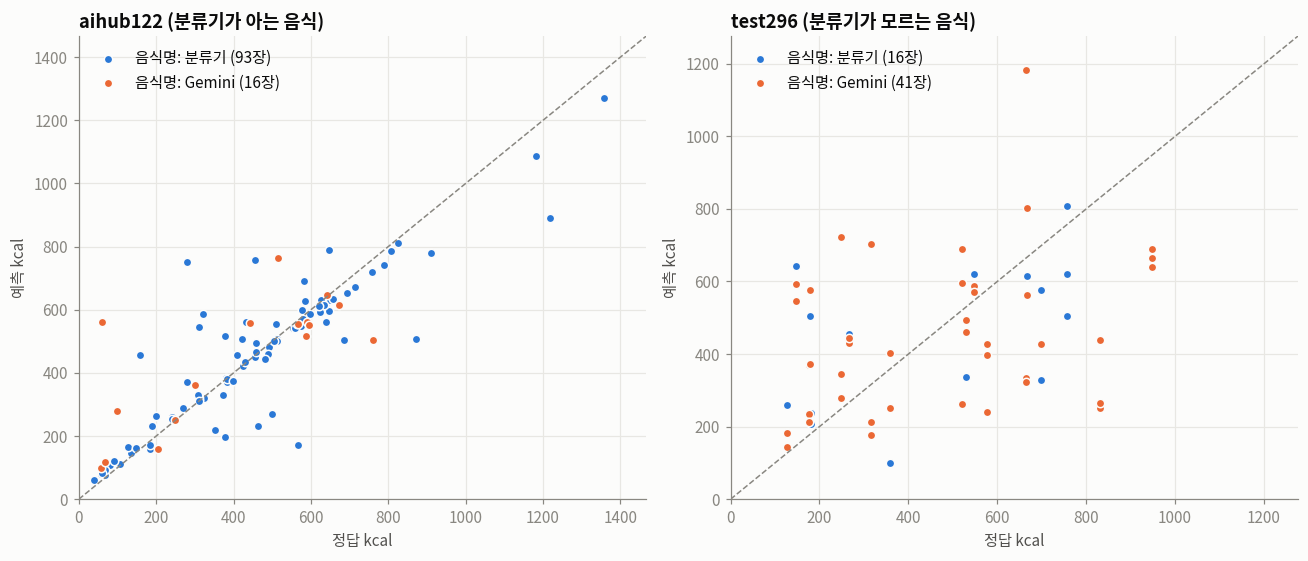

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for a, (title, d) in zip(ax, (("aihub122 (분류기가 아는 음식)", A), ("test296 (분류기가 모르는 음식)", B))):
    lim = max(d["gt_calories"].max(), d["pred_calories"].max()) * 1.08
    a.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1)
    for src, c, lab in (("classifier", C1, "음식명: 분류기"), ("gemini", C2, "음식명: Gemini")):
        s = d[d["name_source"] == src]
        a.scatter(s["gt_calories"], s["pred_calories"], color=c, s=30, edgecolor=SURFACE, lw=1, label=f"{lab} ({len(s)}장)")
    a.set(title=title, xlabel="정답 kcal", ylabel="예측 kcal", xlim=(0, lim), ylim=(0, lim))
    a.legend(frameon=False, loc="upper left")
fig.tight_layout(); save(fig, "04_kcal_scatter"); plt.show()

## 7. test296 음식별 칼로리

회색 = 296 라벨 정답(사진 평균), 파란색 = pipeline 예측 평균.

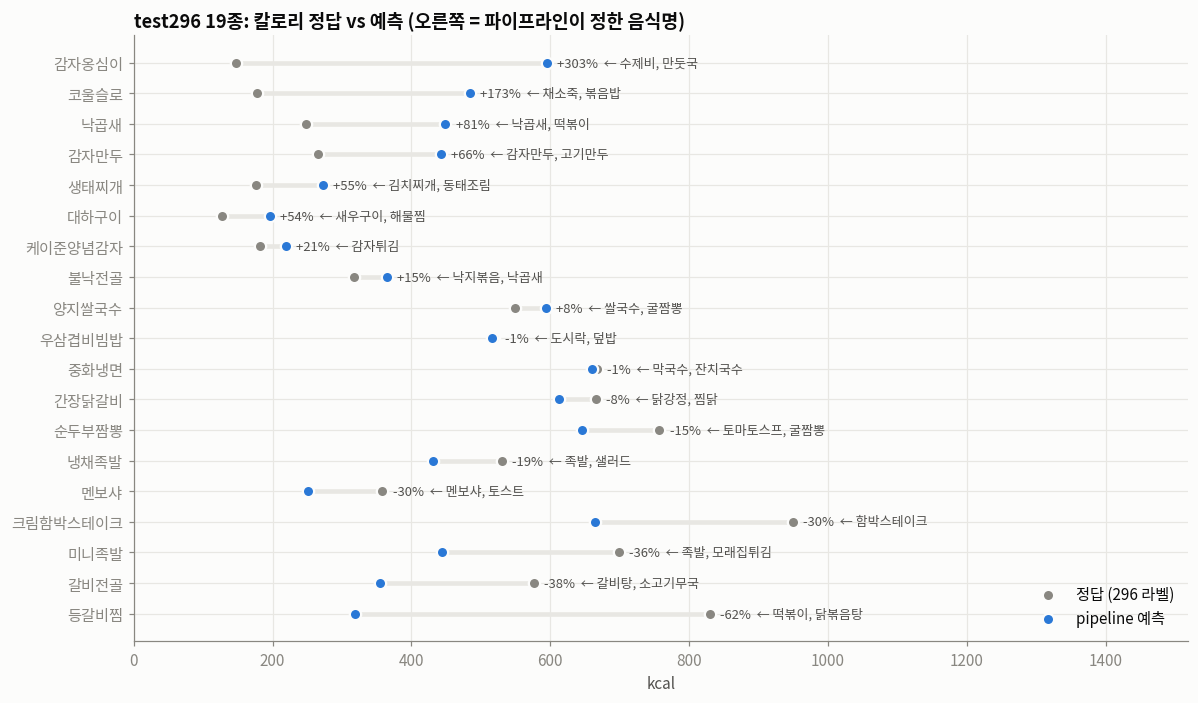

In [8]:
g = B.groupby("gt_name").agg(kcal_gt=("gt_calories", "mean"), kcal_pred=("pred_calories", "mean"),
                              names=("food_name", lambda s: ", ".join(pd.Series(s).value_counts().index[:2]))).reset_index()
g["err"] = 100 * (g["kcal_pred"] - g["kcal_gt"]) / g["kcal_gt"]
g = g.sort_values("err").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 6.5))
for i, r in g.iterrows():
    ax.plot([r["kcal_gt"], r["kcal_pred"]], [i, i], color=GRID, lw=3, solid_capstyle="round", zorder=1)
ax.scatter(g["kcal_gt"], g.index, color=MUTED, s=55, zorder=2, edgecolor=SURFACE, lw=1.5, label="정답 (296 라벨)")
ax.scatter(g["kcal_pred"], g.index, color=C1, s=55, zorder=3, edgecolor=SURFACE, lw=1.5, label="pipeline 예측")
for i, r in g.iterrows():
    ax.text(max(r["kcal_gt"], r["kcal_pred"]) + 15, i, f"{r['err']:+.0f}%  ← {r['names']}", va="center", color=INK2, fontsize=8.5)
ax.set_yticks(g.index, g["gt_name"])
ax.set(title="test296 19종: 칼로리 정답 vs 예측 (오른쪽 = 파이프라인이 정한 음식명)", xlabel="kcal",
       xlim=(0, g[["kcal_gt", "kcal_pred"]].values.max() * 1.6))
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); save(fig, "05_test296_per_food"); plt.show()

## 8. 예시

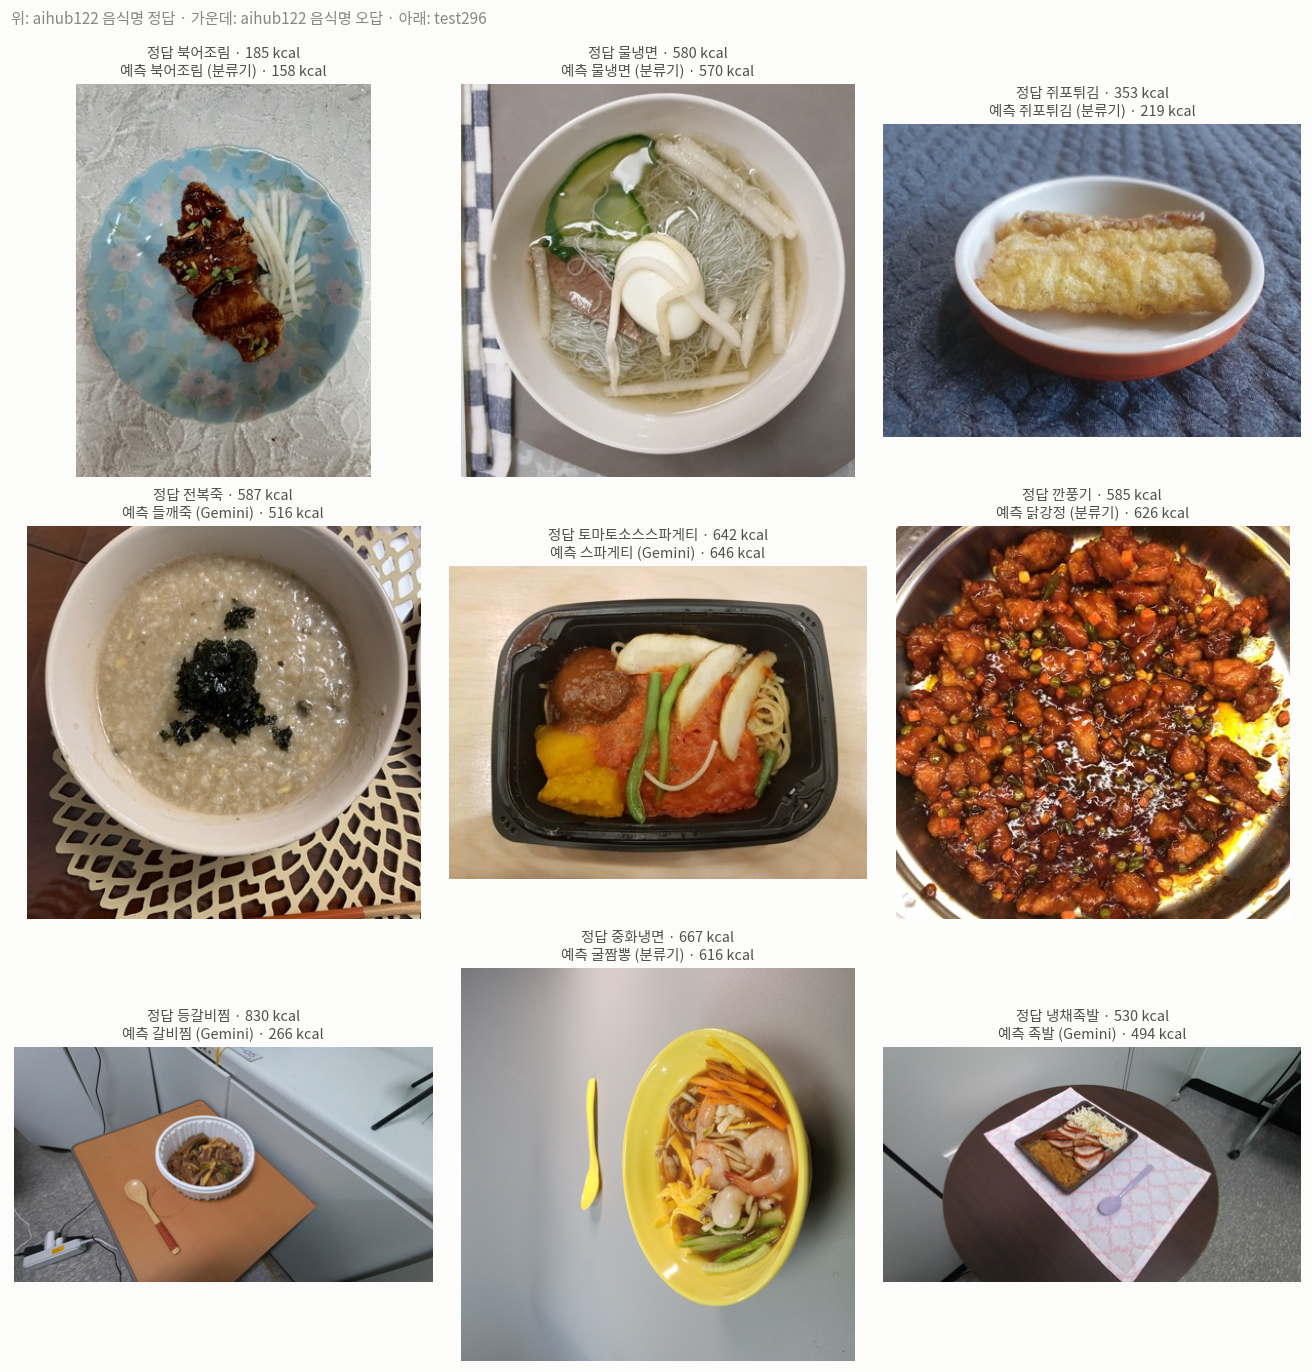

In [9]:
rng = np.random.default_rng(1)
pick = lambda d, n: d.iloc[rng.choice(len(d), min(n, len(d)), replace=False)] if len(d) else d
rows = [pick(A[A["name_correct"]], 3), pick(A[~A["name_correct"]], 3), pick(B, 3)]
fig, axes = plt.subplots(3, 3, figsize=(12, 12.5))
for row_axes, d in zip(axes, rows):
    for a in row_axes:
        a.axis("off")
    for a, (_, r) in zip(row_axes, d.iterrows()):
        im = Image.open(r["image_path"]).convert("RGB"); im.thumbnail((420, 420))
        a.imshow(im)
        src = "분류기" if r["name_source"] == "classifier" else "Gemini"
        a.set_title(f"정답 {r['gt_name']} · {r['gt_calories']:.0f} kcal\n예측 {r['food_name']} ({src}) · {r['pred_calories']:.0f} kcal",
                    fontsize=9.5, loc="center", fontweight="normal", color=INK2)
fig.text(0.01, 0.985, "위: aihub122 음식명 정답 · 가운데: aihub122 음식명 오답 · 아래: test296", color=MUTED, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.98)); save(fig, "06_examples"); plt.show()